# OpenPOPCON, starting from the beginning

Use **Python (ZClass)** and run cells from the top. This notebook assumes
no prior knowledge of OpenPOPCON or these files. We will inspect an input,
run the original SPARC example, adapt it to FIRE H-mode, then try two
extensions. The notebook includes the files' contents where they matter.
If variables become confusing after rerunning cells out of order, choose
**Restart Kernel and Run All Cells**.

### What does a POPCON calculate?

Specify a tokamak's size, magnetic field, current, fuel, and assumptions
about confinement and plasma profiles. Choose an average density and
temperature. The program estimates energy loss and self-heating, then
determines the external **auxiliary heating** required to maintain that
state. Repeat for many density/temperature pairs to make a contour map.

The steady-state accounting is

$$P_{aux}+P_{ohmic}+P_{fusion,heating}=P_{SOL}+P_{radiation}.$$

| Quantity | Meaning |
|---|---|
| Auxiliary heating | External heating, such as radio-frequency heating or neutral beams. |
| Ohmic heating | Heat associated with driving current through a resistive plasma. |
| Fusion heating | Energy deposited by charged fusion products. Most D-T fusion energy leaves as neutrons, so total fusion power is not all plasma heating. |
| Radiation | Energy leaving the confined plasma as electromagnetic radiation. |
| SOL power | Power crossing the confined-plasma boundary into the scrape-off layer (SOL). |
| Confinement time tau_E | An energy-loss timescale; the model uses an empirical scaling rather than solving a full transport problem. |

A POPCON is a steady scoping calculation. A point on a contour is a candidate
state, not a simulated discharge trajectory or a proof of stability.
**Q** here is fusion power divided by auxiliary plus Ohmic heating, not a
gain in net electric power. **H98** is a multiplier of a confinement-time
scaling, not a fraction of heating absorbed by the plasma.

### The code and files in one picture

```text
machine input YAML + plot-settings YAML
    -> op.POPCON(...): load settings into a model object
    -> model.run_POPCON(): calculate the density/temperature grid
    -> model.output: labelled arrays of calculated quantities
    -> model.plot(): contours using the chosen plot settings
```

We follow the package's [usage instructions and worked examples](https://github.com/hansec/OpenPOPCON#usage),
checked against installed version 2.2.0 at commit
`9e70f06df1e8c16df0191730036f5cd00d9e904c`. The pinned
[example runner](https://github.com/hansec/OpenPOPCON/blob/9e70f06df1e8c16df0191730036f5cd00d9e904c/example_run.py)
and [implementation](https://github.com/hansec/OpenPOPCON/blob/9e70f06df1e8c16df0191730036f5cd00d9e904c/openpopcon/core.py)
provide further detail. These are software-use notes; the assignment's
written analysis remains your work.

## 1. Import the tools

`import openpopcon as op` gives the installed package the short name `op`.
`op.POPCON` below is the package's supplied model interface. You do not
need to write a class; you create a model object and call its methods.
A **method** is a function accessed through an object, such as
`fire.run_POPCON()`. An **attribute**, such as `fire.output`, holds data.

| Import | Purpose in this lesson |
|---|---|
| `openpopcon as op` | Set up and run the plasma model. |
| `UNPHYSICAL_PLOT_CUTOFF` | Package threshold used to recognise its failed-point sentinel values. |
| `matplotlib.pyplot as plt` | Make setup diagrams, show figures, and save plots. |
| `numpy as np` | Arrays, trigonometric curves, and grid-point comparisons. |
| `pandas as pd` | Readable tables and CSV exports. |
| `Path`, `yaml` | Locate files and read/write YAML settings. |
| `datetime`, `version`, `json`, `shutil` | Create distinct run folders, record versions/settings, and copy files. These handle files rather than physics. |

In [1]:
from datetime import datetime
from importlib.metadata import version
from pathlib import Path
import json
import shutil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
import openpopcon as op
from openpopcon.core import UNPHYSICAL_PLOT_CUTOFF

## 2. Find the files and set the later exercise parameters

A `Path` represents a file or folder. `/` joins a folder Path to a child
name. The small conditional below finds this lesson's folder both when
running `tutorial.py` and when using the generated notebook. The printout
lets you check where Python is looking for files.

| File or folder, relative to this notebook | What it is used for |
|---|---|
| `tutorial.py`, `tutorial.ipynb` | This lesson as Python source / generated notebook. Edit the Python source first. |
| `inputs/upstream_SPARC/POPCON_input_example.yaml` | Original SPARC machine, composition, profiles, and grid. |
| `inputs/upstream_SPARC/plotsettings.yml` | Original example's plot axes and contour settings. |
| `inputs/fire_h_mode.yaml` | FIRE teaching case, using the same machine-input format. |
| `inputs/plotsettings.yml` | Our FIRE plot settings. This is a different file from SPARC's plot settings. |
| `outputs/<run>/` | Plots, tables, input snapshots, and arrays from one execution. |
| `../references/FIRE/` | The reference papers and a transcription of their machine parameters. |
| `SETUP.md`, `SOURCES.md`, `sources.json` | Environment instructions, provenance, and original-file checksums. |

`.yaml` and `.yml` are the same text format. A YAML dictionary associates
names with values; indentation groups related entries and `#` begins a
comment. These files are settings, not Python functions being executed.
The installed OpenPOPCON code stays in the Conda environment. Printing
`op.__file__` shows where it was imported from.

The values below control the later confinement/limit exercises and an
inspection point. Machine values will come from the FIRE YAML. The 30 MW
cap, beta_N limit of 3, and inspection temperature are teaching choices,
not published FIRE limits or a claimed operating point.

In [2]:
if "__file__" in globals():
    tutorial_dir = Path(__file__).resolve().parent
else:
    tutorial_dir = Path.cwd()
    if not (tutorial_dir / "inputs/fire_h_mode.yaml").exists():
        tutorial_dir = tutorial_dir / "POPCON/OpenPOPCON"

confinement_factors = [0.9, 1.03, 1.15]
auxiliary_power_limit_MW = 30.0
normalized_beta_limit = 3.0
greenwald_fraction_limit = 1.0
sample_density_1e20_m3 = 4.5
sample_average_Ti_keV = 8.0  # an inspection point, not a published FIRE temperature


print("Tutorial folder:", tutorial_dir)
print("Installed package:", op.__file__)

Tutorial folder: /home/youeric/openmc-projects/ZachClass/POPCON/OpenPOPCON
Installed package: /home/youeric/miniforge3/envs/ZClass/lib/python3.12/site-packages/openpopcon/__init__.py


### Create a place for this execution's results

`datetime.now().strftime(...)` makes a timestamp string for the run folder.
`mkdir(parents=True)` creates that folder and missing parents. Each execution
creates a new folder, preserving previous runs. `plot_file` is the FIRE
plotting file Path. `yaml.safe_load` reads the FIRE settings into a normal
Python dictionary named `fire_parameters`; that does not yet run a model.
We inspect that dictionary later, after learning the simpler example.

In [3]:
run_dir = tutorial_dir / "outputs" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
cases_dir = run_dir / "cases"
cases_dir.mkdir(parents=True)
plot_file = tutorial_dir / "inputs/plotsettings.yml"
with open(tutorial_dir / "inputs/fire_h_mode.yaml") as file:
    fire_parameters = yaml.safe_load(file)

print("OpenPOPCON version:", version("openpopcon"))
print("Outputs:", run_dir)

OpenPOPCON version: 2.2.0
Outputs: /home/youeric/openmc-projects/ZachClass/POPCON/OpenPOPCON/outputs/20261015_192828_579090


## 3. Inspect the supplied SPARC input

Start with a supplied example to learn the workflow before changing the
machine. The cell below prints its main values and its grid. Use the
following guide to read the YAML names:

| Input name | Meaning and units |
|---|---|
| `R`, `a` | Major and minor plasma radius, m. R locates the plasma axis; a sets its radial half-width. |
| `kappa`, `delta` | Elongation (vertical stretching) and triangularity (D-shaping). |
| `I_P`, `B_0` | Plasma current in MA and toroidal field on axis in T. |
| `fuel` | Package reaction selector: 2 means D-T. |
| `tipeak_over_tepeak` | Central ion/electron temperature ratio. Ion and electron temperatures can differ. |
| `impurityfractions` | Species number densities relative to electron density, in the order He, Ne, Ar, Kr, Xe, W. |
| `Zeff_target`, `impurity` | Target effective charge and the species index whose fraction is adjusted to reach it at a reference temperature. |
| `scalinglaw`, `H_fac` | Confinement formula name and multiplier, e.g. H98y2 and H98. |
| `Nn`, `NTi` | Number of density samples and average-ion-temperature samples. |
| `nmin_frac`, `nmax_frac` | Average electron density divided by the Greenwald density. |
| `Tmin_keV`, `Tmax_keV` | Range of **volume-average ion temperature**, in keV. A keV is an energy unit used for plasma temperature. |
| `nr` | Radial samples used to integrate assumed profiles; not the number of POPCON states. |
| `parallel`, `verbosity` | Execution threading and diagnostic-message amount; not machine physics. |

Central values occur near the magnetic axis. Volume averages refer to the
whole confined plasma. A peaked profile can have a much hotter core than
its average. Later cells show how the profile parameters determine that.

This example uses 50 density samples by 50 temperature samples: 2,500 states
of one machine. Its `scan` block describes an optional scan of machine
parameters. A plain `POPCON` run ignores that block; `POPCON_scan` uses it.

In [4]:
upstream_input_file = tutorial_dir / "inputs/upstream_SPARC/POPCON_input_example.yaml"
with open(upstream_input_file) as file:
    upstream_raw = yaml.safe_load(file)
print("Input file:", upstream_input_file)
for key in ["R", "a", "kappa", "delta", "I_P", "B_0", "scalinglaw", "H_fac"]:
    print(key, "=", upstream_raw[key])
for key in ["Nn", "NTi", "nmin_frac", "nmax_frac", "Tmin_keV", "Tmax_keV", "nr"]:
    print(key, "=", upstream_raw[key])

Input file: /home/youeric/openmc-projects/ZachClass/POPCON/OpenPOPCON/inputs/upstream_SPARC/POPCON_input_example.yaml
R = 1.85
a = 0.57
kappa = 1.97
delta = 0.54
I_P = 8.7
B_0 = 12.2
scalinglaw = H98y2
H_fac = 1.0
Nn = 50
NTi = 50
nmin_frac = 0.05
nmax_frac = 1.0
Tmin_keV = 3.0
Tmax_keV = 16.0
nr = 100


### Save a working input and create the model

We leave the original file unchanged. The next cell reads it into a
dictionary, sets `parallel` to False for serial execution, and writes a copy
into this run's case folder. `yaml.safe_dump` writes a dictionary as YAML.
The physical values and grid remain the original example's values.

`op.POPCON(settingsfile=..., plotsettingsfile=...)` then loads two files:

- `settingsfile` contains what to calculate: machine, composition, profiles,
  confinement law, and grid.
- `plotsettingsfile` contains how to draw it: axes, colours, and contour levels.

`str(path)` converts a Path to the filename string expected by this API.
The constructor returns a model object, here named `upstream`. This call
loads/checks settings; it does not solve the grid. If `scalinglawfile` is
omitted, the package uses its installed confinement-coefficient file. If
`plotsettingsfile` is omitted, it uses default plotting settings instead.

In [5]:
upstream_dir = cases_dir / "01_upstream_SPARC"
upstream_dir.mkdir()
with open(tutorial_dir / "inputs/upstream_SPARC/POPCON_input_example.yaml") as file:
    upstream_parameters = yaml.safe_load(file)
upstream_parameters["parallel"] = False
with open(upstream_dir / "input.yaml", "w") as file:
    yaml.safe_dump(upstream_parameters, file, sort_keys=False)

upstream = op.POPCON(
    settingsfile=str(upstream_dir / "input.yaml"),
    plotsettingsfile=str(tutorial_dir / "inputs/upstream_SPARC/plotsettings.yml"),
)

Impurity fractions = [0.025      0.         0.00170729 0.         0.         0.        ] calculated from Zeff_target.


### Run the example

`upstream.run_POPCON()` sets up geometry/profiles and calculates the grid.
After it returns, the same object's `output` attribute holds the results.
Unlike CFSPOPCON's `update_dataset` API, this method is used for its effect
on the model object; we do not assign its return value to a Dataset.
The first execution may take longer while Numba compiles the installed
physics routines. That is preparation of the calculation, not a transport run.

In [6]:
upstream.run_POPCON()

Setting up algorithm object
Solving power balance equations


Power balance solutions found. Populating output arrays.
395 of 2500 grid points (15.8%) have no physical solution and are masked in the plot:
     395  impurity radiation exceeds the confinement loss


### Plot and inspect the result

`upstream.plot(...)` draws the already calculated results:

| Argument | What it changes |
|---|---|
| `names=["Paux", "Q"]` | Draw just auxiliary heating and gain, using their styles from the plotting file. |
| `show=False` | Let this notebook control display with `plt.show()`. |
| `savefig=...` | Save the plot at this path as well as displaying it. |

`plt.close("all")` closes finished Matplotlib figures after display.
`.to_netcdf(...)` saves the labelled result arrays in a scientific-data
file. The final print selects three named variables so the output is small.

**Reading the picture:** choose one temperature on x and one density on y.
A line labelled 10 in the Q family means fusion gain 10 there; a line in the
auxiliary-power family gives required MW. Their intersection describes one
candidate state. Grey shading identifies points the package marked invalid.
Contour levels do not select the operating temperature automatically.

Plotting Paux with levels [1.0e-01 1.0e+00 1.0e+01 2.5e+01 5.0e+01 1.0e+02 5.0e+02 2.0e+03] and options ['r', 3, '$P_{aux}$', 12, '%.2d']
Plotting Q with levels [  0.5   1.    2.    5.   10.   25.   50.  100. ] and options ['orange', 2, '$Q$', 12, '%.f']


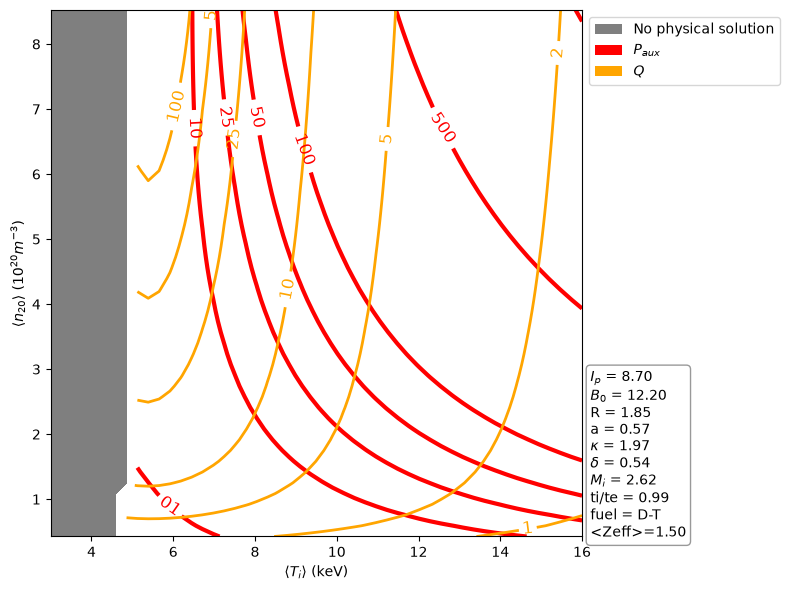

<xarray.Dataset> Size: 63kB
Dimensions:     (n_index: 50, T_index: 50)
Coordinates:
    n_G_frac    (n_index) float64 400B 0.05 0.06939 0.08878 ... 0.9806 1.0
    n_e_20_max  (n_index) float64 400B 0.5791 0.8036 1.028 ... 11.13 11.36 11.58
    n_e_20_avg  (n_index) float64 400B 0.4262 0.5914 0.7567 ... 8.358 8.524
    T_i_max     (T_index) float64 400B 8.206 8.932 9.658 ... 42.32 43.04 43.77
    T_i_avg     (T_index) float64 400B 3.0 3.265 3.531 ... 15.47 15.73 16.0
    T_e_max     (T_index) float64 400B 8.294 9.028 9.761 ... 42.77 43.5 44.24
    T_e_avg     (T_index) float64 400B 3.032 3.3 3.568 ... 15.64 15.9 16.17
Dimensions without coordinates: n_index, T_index
Data variables:
    Paux        (n_index, T_index) float64 20kB 1e+05 1e+05 ... 2.078e+03
    Pfusion     (n_index, T_index) float64 20kB 0.2909 0.3802 ... 3.781e+03
    Q           (n_index, T_index) float64 20kB 2.909e-06 3.802e-06 ... 1.819
Attributes:
    machine:             SPARC
    settings:            {"settingsfile

In [7]:
upstream.plot(show=False, savefig=str(run_dir / "01_upstream_SPARC.png"), names=["Paux", "Q"])
plt.show()
plt.close("all")
upstream.output.to_netcdf(upstream_dir / "results.nc")
print(upstream.output[["Paux", "Pfusion", "Q"]])

### What is `upstream.output`?

It is an xarray Dataset: a collection of arrays accessed by quantity name.
`output["Paux"]` is one DataArray with labelled dimensions. `n_index` and
`T_index` are integer-position dimensions, not physical density/temperature
values. Physical coordinates such as `n_e_20_avg` and `T_i_avg` label them.
This is why selecting array position zero is different from selecting a
physical density of zero.

| Result name | Meaning |
|---|---|
| `n_e_20_avg`, `n_e_20_max` | Volume-average / central electron density, in 10^20 m^-3. |
| `T_i_avg`, `T_i_max` | Volume-average / central ion temperature, keV. |
| `T_e_avg`, `T_e_max` | Corresponding electron temperatures. |
| `Paux`, `Pohmic`, `Pfusionheating` | Auxiliary, Ohmic, and deposited fusion heating, MW. |
| `Pfusion` | Total fusion power, MW, including power that leaves as neutrons. |
| `Pbrems`, `Psynch`, `Pimprad`, `Prad` | Bremsstrahlung, synchrotron, impurity, and total radiation powers, MW. |
| `tauE`, `Wtot` | Confinement time in s and stored thermal energy in MJ. |
| `Q` | Total fusion power / (auxiliary + Ohmic heating). |
| `betaN` | Package normalized-beta diagnostic, with beta expressed in percent. |

OpenPOPCON uses unit attributes rather than attaching Pint quantities here.
Keep those conventions when taking raw numbers from `.values`.

In [8]:
print("Paux dimensions:", upstream.output["Paux"].dims)
print("Paux shape:", upstream.output["Paux"].shape)
print("Paux units:", upstream.output["Paux"].attrs["units"])
print("First density samples:", upstream.output["n_e_20_avg"].values[:3])
print("First average Ti samples:", upstream.output["T_i_avg"].values[:3])

Paux dimensions: ('n_index', 'T_index')
Paux shape: (50, 50)
Paux units: MW
First density samples: [0.42617667 0.59142885 0.75668103]
First average Ti samples: [3.         3.26530612 3.53061224]


## 4. Read the FIRE input, including its profiles

The file below adapts the example to FIRE H-mode. The machine values are
R = 2.14 m, a = 0.595 m, B = 10 T, Ip = 7.7 MA, and H98 = 1.03, from
[Meade et al. (2002), Table I](https://fire.pppl.gov/fec2002_FT2_6_reprint4.pdf).
We use the published areal elongation 1.85 as this model's single elongation
and separatrix triangularity 0.7. This analytic representation is not a
reconstructed FIRE magnetic equilibrium.

### What are the extra profile inputs?

Blank `gfilename` means use analytic geometry rather than an external
gEQDSK magnetic-equilibrium file. Blank `profsfilename` means use the
analytic profiles rather than a supplied profile-data file. If external
filenames are provided later, the package resolves them relative to the
machine-input file and they can affect which settings control the geometry.

The analytic profile shape is

$$f(\rho)/f(0)=offset+(1-offset)(1-\rho^{alpha1})^{alpha2}.$$

`rho` is a normalized radial coordinate, near zero at the core and one at
the boundary. `alpha1` and `alpha2` change how sharply the profile falls;
`offset` sets the edge value relative to the centre.

| Prefix in the YAML | Which profile it describes |
|---|---|
| `j_` | Current density. Its assumed shape affects the resistive calculation. |
| `ne_`, `ni_` | Electron and fuel-ion density shapes. |
| `Ti_`, `Te_` | Ion and electron temperature shapes. |

`nr=100` gives radial integration samples. It is independent of the 31 by
33 density/temperature POPCON grid. Our shapes approximate central/average
peaking of 1.1 for density and 2.5 for temperature. The temperature's small
edge floor avoids zero-temperature resistivity. Equal Ti/Te, the current
profile, impurity species, and this edge treatment are modelling choices.

`Zeff_target=1.5` specifies effective charge, a charge-weighted measure of
composition. `impurity=2` selects argon in the package's zero-based species
order. The package adjusts that species at a reference temperature; Zeff
need not equal 1.5 everywhere. Impurities also dilute the reacting D-T fuel.
`resistivity_model="Jardin"` selects the installed resistivity treatment;
it is a model name, not a file we created in this folder.

In [9]:
print((tutorial_dir / "inputs/fire_h_mode.yaml").read_text())

# FIRE H-mode: Meade et al. (2002), Table I.
# This is a teaching input, not a reconstruction of the original equilibrium.
name: FIRE_H_mode
R: 2.14                 # major radius [m]
a: 0.595                # minor radius [m]
kappa: 1.85             # use areal elongation for the single-shape model
delta: 0.7              # separatrix triangularity
I_P: 7.7                # plasma current [MA]
B_0: 10.0               # field on axis [T]
tipeak_over_tepeak: 1.0  # teaching assumption: Ti = Te
fuel: 2                 # equal D-T mixture

# Species are a modelling choice; Table I gives Zeff, not these concentrations.
# OpenPOPCON adjusts argon to meet Zeff_target at its reference temperature.
impurityfractions: [0.025, 0.0, 0.0, 0.0, 0.0, 0.0]
Zeff_target: 1.5
impurity: 2             # argon
scalinglaw: H98y2
H_fac: 1.03
nr: 100
gfilename: ""           # analytic geometry; no equilibrium file is required
profsfilename: ""       # analytic profiles

# f(rho)/f(0) = offset + (1-offset)*(1-

### Set up the model before solving the grid

We copy the FIRE input into this run's case folder, construct another
`op.POPCON` object called `fire`, and call
`fire.run_POPCON(setuponly=True)`. That flag prepares geometry and profiles
without solving all density/temperature states. The object's `algorithms`
attribute now provides the package's profile/integration methods.

In [10]:
fire_case_dir = cases_dir / "02_FIRE_H_mode"
fire_case_dir.mkdir()
shutil.copy2(tutorial_dir / "inputs/fire_h_mode.yaml", fire_case_dir / "input.yaml")
fire = op.POPCON(settingsfile=str(fire_case_dir / "input.yaml"), plotsettingsfile=str(plot_file))
fire.run_POPCON(setuponly=True)

Impurity fractions = [0.025      0.         0.00170578 0.         0.         0.        ] calculated from Zeff_target.


### Check what geometry and profiles were actually set up

The next cell makes a shape sketch and reads the package's own normalized
profiles. `get_profile(rho, profile_id)` returns a profile at the requested
radial samples. In this API the IDs are 1 for electron density and 3 for ion
temperature. Other IDs are 0 for current, 2 for ion density, and 4 for electron
temperature. The IDs are package conventions, not a formula you must derive.

`volume_integral(rho, profile)` integrates that shape over the model volume.
Dividing by `algorithms.V` gives its volume average. Central value divided
by that average gives the printed peaking factor. Normalization makes the
central profile values near one; the real density/temperature amplitude is
assigned separately at each POPCON state.

`plt.subplots(1, 2)` gives one Figure with two Axes, accessed as `axes[0]`
and `axes[1]`. The trigonometric boundary is a D-shaped drawing using the
input geometry; it is not an equilibrium solver. Equal axis scale makes a
metre look the same vertically and horizontally. Profile curves come from
the package itself, not from that drawing.

electron density: central / volume average = 1.105
ion temperature: central / volume average = 2.468


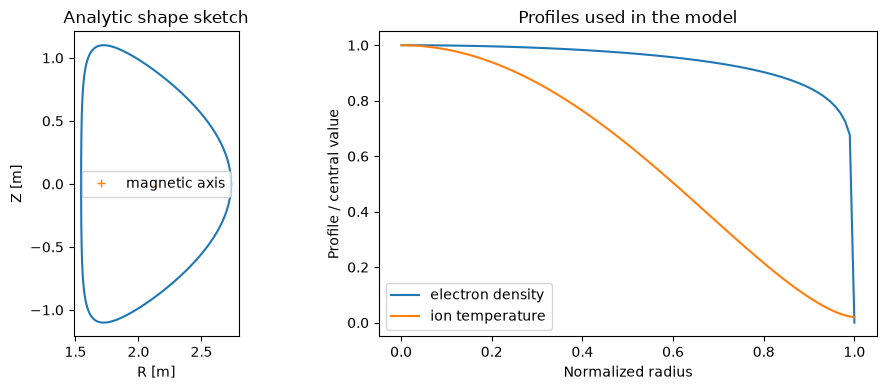

In [11]:
rho = fire.algorithms.sqrtpsin
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
theta = np.linspace(0, 2 * np.pi, 300)
# This is a shape sketch; the package computes its own analytic volume.
R_surface = fire_parameters["R"] + fire_parameters["a"] * np.cos(
    theta + np.arcsin(fire_parameters["delta"]) * np.sin(theta)
)
Z_surface = fire_parameters["kappa"] * fire_parameters["a"] * np.sin(theta)
axes[0].plot(R_surface, Z_surface)
axes[0].plot(fire_parameters["R"], 0, "+", label="magnetic axis")
axes[0].set(xlabel="R [m]", ylabel="Z [m]", title="Analytic shape sketch")
axes[0].set_aspect("equal")
axes[0].legend()
for profile_id, label in [(1, "electron density"), (3, "ion temperature")]:
    profile = fire.algorithms.get_profile(rho, profile_id)
    average = fire.algorithms.volume_integral(rho, profile) / fire.algorithms.V
    axes[1].plot(rho, profile, label=label)
    print(f"{label}: central / volume average = {profile[0] / average:.3f}")
axes[1].set(xlabel="Normalized radius", ylabel="Profile / central value", title="Profiles used in the model")
axes[1].legend()
fig.tight_layout()
fig.savefig(run_dir / "02_FIRE_setup.png", dpi=150)
plt.show()
plt.close(fig)

## 5. Calculate the FIRE grid

Calling `fire.run_POPCON()` with no `setuponly` flag now solves all 1,023
states. The density range is entered as a fraction of

$$n_G[10^{20}\,m^{-3}]=I_p[MA]/(\pi a^2[m^2]).$$

`nmin_frac` and `nmax_frac` use volume-average electron density divided by
this scale, as a proxy for the usual line-average Greenwald fraction.
Temperatures remain volume-average **ion** temperatures in this tool.
The paper separately lists 4.5e20 m^-3 and a Greenwald fraction of 0.7;
applying this simple convention to 4.5 gives about 0.65, so do not force
those separately reported values to be identical definitions.

In [12]:
fire.run_POPCON()

Setting up algorithm object
Solving power balance equations
Power balance solutions found. Populating output arrays.
217 of 1023 grid points (21.2%) have no physical solution and are masked in the plot:
     217  impurity radiation exceeds the confinement loss


### Understand the plot file before plotting

The FIRE plot settings are printed below. `xax: T_i_av` chooses average Ti;
`yax: n20_av` chooses average electron density in 10^20 m^-3. These plot
selector names map to `T_i_avg` and `n_e_20_avg` in the result Dataset.

In each `plotoptions` entry, `manuallevels` specifies the contour values.
For `Paux`, they are MW; for Q, they are dimensionless gain values. `color`,
`linewidth`, `fontsize`, and `fmt` control drawing/label formatting.
`fill_invalid` shades points marked as invalid. Changing plot settings
changes the drawing, not the calculated grid. For later edits, reload
settings with `fire.update_plotsettings(str(plot_file))` and redraw.

In [13]:
print(plot_file.read_text())

xax: T_i_av
yax: n20_av
figsize: [9, 6]
fill_invalid: true
plotoptions:
  Paux:
    plot: true
    color: tab:red
    linewidth: 1.5
    label: '$P_{aux}$ [MW]'
    fontsize: 9
    spacing: manual
    manuallevels: [0, 5, 15, 30, 60, 100]
    scale: specified
    levels: 6
    fmt: '%.0f'
  Q:
    plot: true
    color: tab:blue
    linewidth: 1.5
    label: '$Q$'
    fontsize: 9
    spacing: manual
    manuallevels: [1, 5, 10, 20]
    scale: specified
    levels: 4
    fmt: '%.0f'
  betaN:
    plot: false



Plotting Paux with levels [  0.   5.  15.  30.  60. 100.] and options ['tab:red', 1.5, '$P_{aux}$ [MW]', 9, '%.0f']
Plotting Q with levels [ 1.  5. 10. 20.] and options ['tab:blue', 1.5, '$Q$', 9, '%.0f']


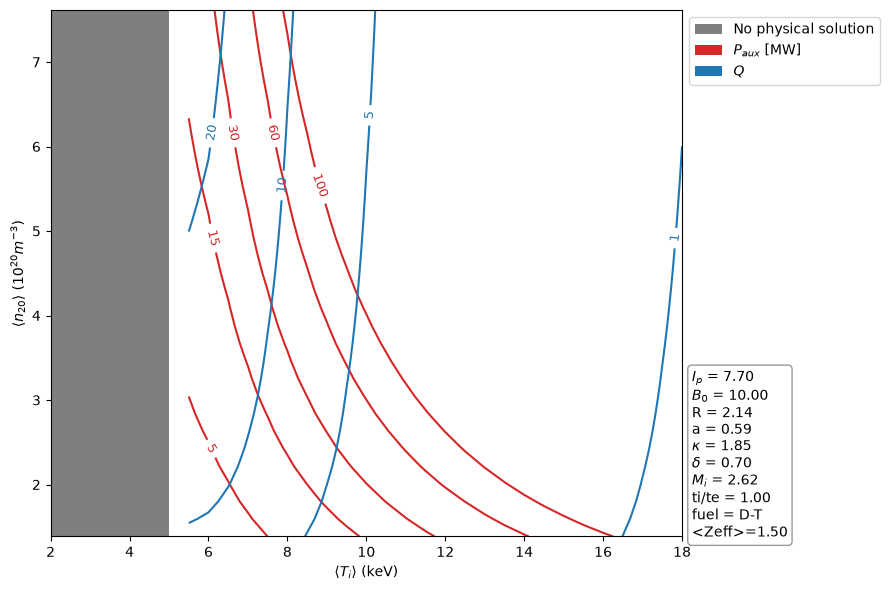

n_G = 6.923 x 10^20 m^-3
Inspection-point density / n_G = 0.650


In [14]:
fire.plot(show=False, savefig=str(run_dir / "03_FIRE_POPCON.png"), names=["Paux", "Q"])
plt.show()
plt.close("all")
fire.output.to_netcdf(fire_case_dir / "results.nc")

greenwald_density = fire_parameters["I_P"] / (np.pi * fire_parameters["a"] ** 2)
print(f"n_G = {greenwald_density:.3f} x 10^20 m^-3")
print(f"Inspection-point density / n_G = {sample_density_1e20_m3 / greenwald_density:.3f}")

## 6. Inspect one point rather than only the contour map

`single_point(n_G_frac, Ti_av, ...)` takes **density fraction** and
**average ion temperature**. It does not take density in particles/m^3 or
central temperature. We convert the chosen density to a fraction first.
`show=False` lets us save and display the returned diagnostic figure.
The method prints the power budget and creates radial diagnostic plots;
it does not return an xarray Dataset for that point.

The code then locates the nearest samples in the previously solved grid.
`abs(array - requested_value).argmin()` gives the position of the smallest
distance. `.isel(n_index=..., T_index=...)` selects by those integer
positions. It may give slightly different coordinates from the requested
point; the printed coordinates show the values actually sampled. By
contrast, `single_point` calculates at the requested coordinates directly.


Params:
n_i_average = 4.164198182192764 x 10^20 m^-3
n_e_average = 4.500 x 10^20 m^-3
n_G = 6.923 x 10^20 m^-3
n_i_axis = 4.602 x 10^20 m^-3
n_e_axis = 4.973 x 10^20 m^-3
Ti_average = 8.0 keV
Ti_axis = 19.7 keV
Solution:
P_aux = 43.92 MW
P_fusion = 392.37 MW
P_SOL = 86.23 MW
P_load = 1.200 MW/m^2
P_ohmic = 0.108 MW
P_brems = 13.214 MW
P_synch = 2.691 MW
P_imprad = 20.663 MW
P_rad = 36.57 MW
P_heat = 106.89 MW
P_alpha = 78.47 MW
P_dd = 0.450 MW
P_dt = 391.92 MW
Wtot/TauE = 106.89 MW
f_rad = 0.298 
tauE = 0.435 s
Q = 8.912 
H89 = 1.91
H98 = 1.03
vloop = 0.0140 V
betaN = 2.289



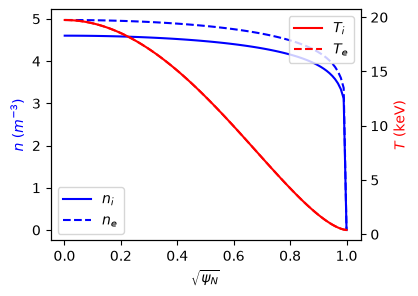

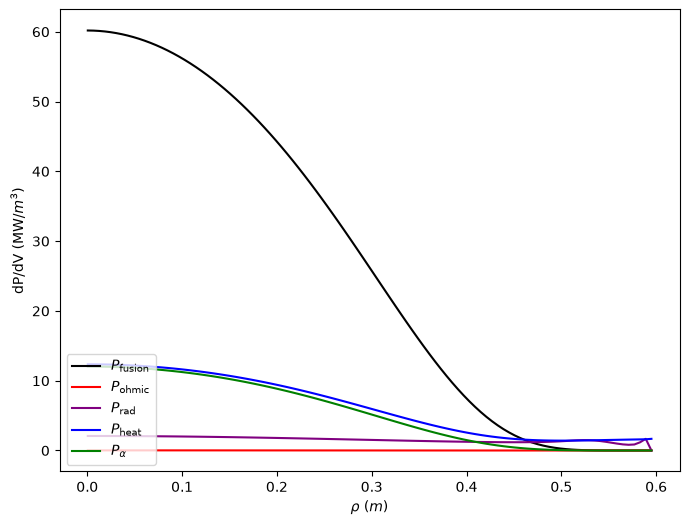

<xarray.Dataset> Size: 112B
Dimensions:     ()
Coordinates:
    n_G_frac    float64 8B 0.65
    n_e_20_max  float64 8B 4.973
    n_e_20_avg  float64 8B 4.5
    T_i_max     float64 8B 19.74
    T_i_avg     float64 8B 8.0
    T_e_max     float64 8B 19.74
    T_e_avg     float64 8B 8.0
Data variables:
    Paux        float64 8B 43.92
    Pfusion     float64 8B 392.4
    Pohmic      float64 8B 0.108
    Prad        float64 8B 36.57
    Q           float64 8B 8.912
    tauE        float64 8B 0.4353
    betaN       float64 8B 2.289
Attributes:
    machine:             FIRE_H_mode
    settings:            {"settingsfile": "/home/youeric/openmc-projects/Zach...
    scalinglaws:         {"H89": {"scaling_const": 0.048, "M_i_alpha": 0.5, "...
    openpopcon_version:  2.2.0


In [15]:
fire.single_point(sample_density_1e20_m3 / greenwald_density, sample_average_Ti_keV, show=False)
plt.gcf().savefig(run_dir / "04_FIRE_single_point.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close("all")

density_index = int(np.abs(fire.output.n_e_20_avg.values - sample_density_1e20_m3).argmin())
temperature_index = int(np.abs(fire.output.T_i_avg.values - sample_average_Ti_keV).argmin())
nearest = fire.output.isel(n_index=density_index, T_index=temperature_index)
print(nearest[["Paux", "Pfusion", "Pohmic", "Prad", "Q", "tauE", "betaN"]])

### Interpret the power terms using this package's convention

`Pfusionheating + Pohmic + Paux` is the total heating. In the installed
version, `Pheat` subtracts bremsstrahlung and synchrotron from that total
before evaluating its confinement scaling. `Pconf = Wtot/tauE`,
`Ploss = Pconf + Pbrems + Psynch`, and `Psol = Pconf - Pimprad`.
Impurity radiation therefore reduces the power crossing the boundary.
Use the output names with these definitions; adding all radiation to
`Pconf` would count impurity radiation twice in this implementation.

On a positive-heating valid point, total heating should equal `Ploss`, and
`Psol + Prad` should equal that loss. The generic power balance at the top
is the same accounting, with the package-specific terms defined here.

### Recognise missing solutions and export a grid table

The package puts a large sentinel in `Paux` at invalid states.
`UNPHYSICAL_PLOT_CUTOFF` is its threshold for recognising those entries;
it is not a chosen heating-capacity limit. A **mask** is one True/False
value per state. `np.isfinite` rejects missing/infinite values and the
second comparison rejects sentinels. `&` combines conditions point by point.

`.where(valid)` replaces rejected output values with missing values.
`.to_dataframe().reset_index()` turns the labelled grid into rows/columns,
and `to_csv(index=False)` saves it without an extra row-number column.
Machine columns record which input produced each row. NetCDF retains unit
attributes; a CSV only retains the names/numbers, so keep its unit conventions.
Zero-clipped auxiliary power is a separate case: it can indicate excess
self-heating, not an exact balanced temperature. The limits exercise will
exclude it.

In [16]:
valid = np.isfinite(fire.output.Paux) & (fire.output.Paux < UNPHYSICAL_PLOT_CUTOFF)
table = fire.output.where(valid).to_dataframe().reset_index()
table["R_m"] = fire_parameters["R"]
table["a_m"] = fire_parameters["a"]
table["B_T"] = fire_parameters["B_0"]
table["Ip_MA"] = fire_parameters["I_P"]
table["H98"] = fire_parameters["H_fac"]
table.to_csv(run_dir / "FIRE_grid.csv", index=False)

## 7. Extension: change H98 and run the same grid again

H98 multiplies the selected energy-confinement scaling. We use three
assumptions for the same machine, at the same density/temperature samples.
We inspect the same grid point in each case, rather than comparing maxima
that could occur at different states.

Follow one pass through the loop:

1. `enumerate` supplies a panel position and one H98 value.
2. Copy the FIRE dictionary and replace only `H_fac`. Since we replace a
   single scalar here, a normal dictionary copy is sufficient.
3. Save the modified YAML and construct/run a fresh model. This prevents
   previously calculated values from being reused as if they were new.
4. Save the arrays and draw into the matching Axes with `ax=...`.
   `infobox=False` and `legend=False` avoid repeated boxes in small panels.
   Red is auxiliary power; blue is Q, with the same levels in all panels.
5. Use `.isel` at the same grid indices and append one dictionary of numbers.
   `pd.DataFrame(scan_rows)` collects those dictionaries into a table.

OpenPOPCON also supplies `POPCON_scan` for machine-parameter sweeps; this
explicit one-parameter loop exposes exactly which setting is being changed.

Impurity fractions = [0.025      0.         0.00170578 0.         0.         0.        ] calculated from Zeff_target.
Setting up algorithm object
Solving power balance equations


Power balance solutions found. Populating output arrays.
186 of 1023 grid points (18.2%) have no physical solution and are masked in the plot:
     186  impurity radiation exceeds the confinement loss
Plotting Paux with levels [  0.   5.  15.  30.  60. 100.] and options ['tab:red', 1.5, '$P_{aux}$ [MW]', 9, '%.0f']
Plotting Q with levels [ 1.  5. 10. 20.] and options ['tab:blue', 1.5, '$Q$', 9, '%.0f']
Impurity fractions = [0.025      0.         0.00170578 0.         0.         0.        ] calculated from Zeff_target.
Setting up algorithm object
Solving power balance equations


Power balance solutions found. Populating output arrays.
217 of 1023 grid points (21.2%) have no physical solution and are masked in the plot:
     217  impurity radiation exceeds the confinement loss
Plotting Paux with levels [  0.   5.  15.  30.  60. 100.] and options ['tab:red', 1.5, '$P_{aux}$ [MW]', 9, '%.0f']
Plotting Q with levels [ 1.  5. 10. 20.] and options ['tab:blue', 1.5, '$Q$', 9, '%.0f']
Impurity fractions = [0.025      0.         0.00170578 0.         0.         0.        ] calculated from Zeff_target.
Setting up algorithm object
Solving power balance equations


Power balance solutions found. Populating output arrays.
248 of 1023 grid points (24.2%) have no physical solution and are masked in the plot:
     248  impurity radiation exceeds the confinement loss
37 of 1023 grid points need no auxiliary heating (P_aux cannot be less than zero, setting P_aux = 0).
Plotting Paux with levels [  0.   5.  15.  30.  60. 100.] and options ['tab:red', 1.5, '$P_{aux}$ [MW]', 9, '%.0f']
Plotting Q with levels [ 1.  5. 10. 20.] and options ['tab:blue', 1.5, '$Q$', 9, '%.0f']


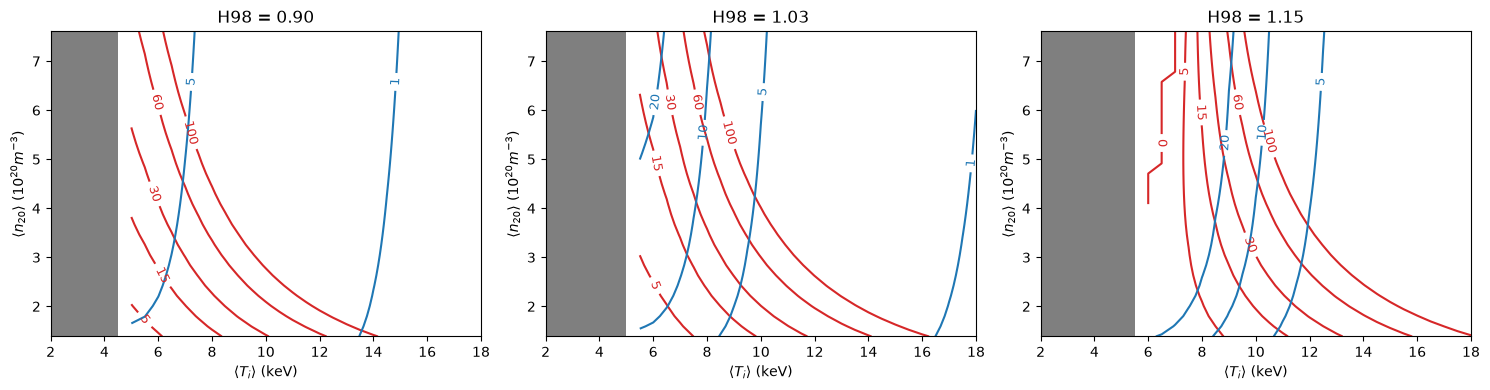

       case  H98  R_m   a_m  B_T  Ip_MA  density_1e20_m3  Ti_keV    Paux_MW  Pfusion_MW         Q  valid
03_H98_0.90 0.90 2.14 0.595 10.0    7.7          4.50008     8.0 102.214190  392.380497  3.834755   True
03_H98_1.03 1.03 2.14 0.595 10.0    7.7          4.50008     8.0  43.921784  392.380497  8.911709   True
03_H98_1.15 1.15 2.14 0.595 10.0    7.7          4.50008     8.0  11.940799  392.380497 32.565977   True


In [17]:
scan_rows = []
fig, axes = plt.subplots(1, len(confinement_factors), figsize=(15, 4), squeeze=False)
for column, H98 in enumerate(confinement_factors):
    case_name = f"03_H98_{H98:.2f}"
    case_dir = cases_dir / case_name
    case_dir.mkdir()
    parameters = fire_parameters.copy()
    parameters["H_fac"] = H98
    with open(case_dir / "input.yaml", "w") as file:
        yaml.safe_dump(parameters, file, sort_keys=False)
    model = op.POPCON(settingsfile=str(case_dir / "input.yaml"), plotsettingsfile=str(plot_file))
    model.run_POPCON()
    model.output.to_netcdf(case_dir / "results.nc")
    model.plot(show=False, ax=axes[0, column], names=["Paux", "Q"], infobox=False,
               legend=False, title=f"H98 = {H98:.2f}")
    point = model.output.isel(n_index=density_index, T_index=temperature_index)
    scan_rows.append({
        "case": case_name, "H98": H98, "R_m": parameters["R"],
        "a_m": parameters["a"], "B_T": parameters["B_0"], "Ip_MA": parameters["I_P"],
        "density_1e20_m3": float(point.n_e_20_avg), "Ti_keV": float(point.T_i_avg),
        "Paux_MW": float(point.Paux), "Pfusion_MW": float(point.Pfusion), "Q": float(point.Q),
        "valid": bool(np.isfinite(point.Paux) & (point.Paux < UNPHYSICAL_PLOT_CUTOFF)),
    })
fig.tight_layout()
fig.savefig(run_dir / "05_confinement_scan.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
scan_table = pd.DataFrame(scan_rows)
scan_table.to_csv(run_dir / "confinement_scan.csv", index=False)
print(scan_table.to_string(index=False))

## 8. Extension: shade points meeting selected operating limits

A mathematical power balance is only one condition for an operating point.
We now combine the `valid` mask with several additional conditions:

| Condition | Meaning |
|---|---|
| `Paux > 0` | Exclude the zero-clipped self-heating region. |
| `Paux <= auxiliary_power_limit_MW` | Keep required heating within our illustrative capacity. |
| `betaN <= normalized_beta_limit` | Apply an illustrative pressure-related limit; it is not an MHD stability calculation. |
| `n_G_frac <= greenwald_fraction_limit` | Apply the density-limit proxy described above. |

Beta measures plasma pressure relative to magnetic pressure. Conventional
numerical beta_N normalizes beta in percent by current/(minor radius times
field), using MA, m, and T. `betaN` already uses that numerical convention.
Do not multiply the output by 100 a second time.

`allowed` is another grid of True/False values. `astype(int)` changes those
to 1/0, and `contourf` shades the ones pale green. It does not delete data
or change the physics calculation. The dashed purple line marks the beta
bound; the dotted black line marks the density bound. The retained region
also obeys the heating cap, even though that cap is not a separate shaded
colour. `ravel()` flattens the mask in row order to add it to the exported
grid table, whose order is density first, temperature second.

These checks do not establish H-mode access, pulse duration, divertor
compatibility, magnet feasibility, or all plasma stability constraints.
This tutorial does not add an independent L-H threshold model to OpenPOPCON.

Plotting Paux with levels [  0.   5.  15.  30.  60. 100.] and options ['tab:red', 1.5, '$P_{aux}$ [MW]', 9, '%.0f']
Plotting Q with levels [ 1.  5. 10. 20.] and options ['tab:blue', 1.5, '$Q$', 9, '%.0f']


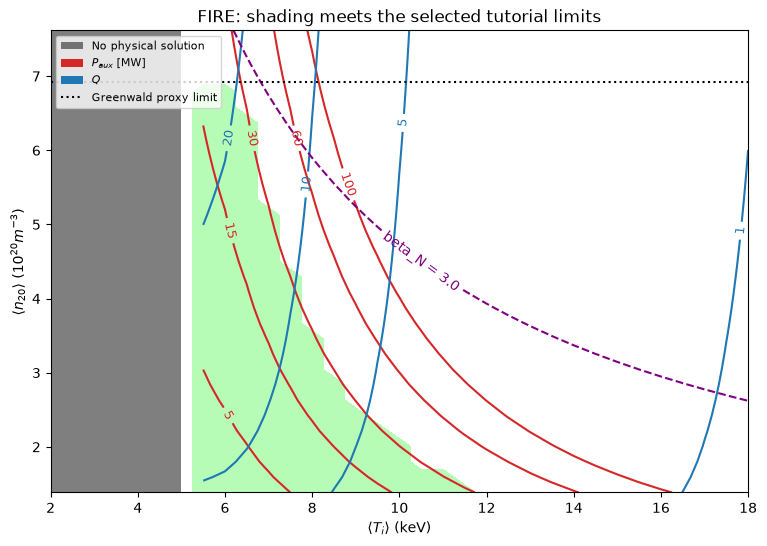

In [18]:
allowed = (
    valid
    & (fire.output.Paux > 0)
    & (fire.output.Paux <= auxiliary_power_limit_MW)
    & (fire.output.betaN <= normalized_beta_limit)
    & (fire.output.n_G_frac <= greenwald_fraction_limit)
)
fig, ax = plt.subplots(figsize=(9, 6))
ax.contourf(fire.output.T_i_avg, fire.output.n_e_20_avg, allowed.astype(int),
            levels=[0.5, 1.5], colors=["palegreen"], alpha=0.7)
fire.plot(show=False, ax=ax, names=["Paux", "Q"], infobox=False,
          title="FIRE: shading meets the selected tutorial limits")
beta_contour = ax.contour(fire.output.T_i_avg, fire.output.n_e_20_avg, fire.output.betaN,
                         levels=[normalized_beta_limit], colors="purple", linestyles="--")
ax.clabel(beta_contour, fmt="beta_N = %.1f")
ax.axhline(greenwald_density * greenwald_fraction_limit, color="black", linestyle=":", label="Greenwald proxy limit")
ax.legend(loc="upper left", fontsize=8)
fig.savefig(run_dir / "06_selected_operating_limits.png", dpi=150, bbox_inches="tight")
plt.show()
plt.close(fig)
table["meets_selected_limits"] = allowed.values.ravel()
table.to_csv(run_dir / "FIRE_grid.csv", index=False)

## 9. Save the run settings and find the files

The remaining code copies the plotting file and writes a JSON dictionary
containing version, inputs, exercise values, and point counts. `json.dump`
writes readable settings; it does not run another calculation.

```text
outputs/<run>/
    01_upstream_SPARC.png        supplied example
    02_FIRE_setup.png            shape and normalized profiles
    03_FIRE_POPCON.png           FIRE contours
    04_FIRE_single_point.png     selected state's diagnostics
    05_confinement_scan.png      H98 exercise
    06_selected_operating_limits.png
    FIRE_grid.csv               one row per density/temperature pair
    confinement_scan.csv        same point at each H98
    run_summary.json            inputs, version, limits, counts
    cases/<case_name>/input.yaml, results.nc
```

A full results file can later be read with xarray:

```python
import xarray as xr
results = xr.load_dataset("outputs/<run>/cases/02_FIRE_H_mode/results.nc")
```

Replace `<run>` with an actual run folder. The package also offers
`model.write_output(...)` / `read_output(...)` for its own bundled archive
format. This lesson saves arrays and inputs explicitly so you can see each
file's purpose.

In [19]:
shutil.copy2(plot_file, run_dir / "plotsettings.yml")
metadata = {
    "openpopcon_version": version("openpopcon"),
    "reference": "Meade et al. 2002, Table I, FIRE H-mode",
    "fire_parameters": fire_parameters,
    "confinement_factors": confinement_factors,
    "inspection_density_1e20_m3": sample_density_1e20_m3,
    "inspection_average_Ti_keV": sample_average_Ti_keV,
    "tutorial_limits": {"Paux_MW": auxiliary_power_limit_MW,
                        "beta_N": normalized_beta_limit, "density_over_nG": greenwald_fraction_limit},
    "grid_points": int(fire.output.Paux.size),
    "valid_points": int(valid.sum()),
    "points_meeting_selected_limits": int(allowed.sum()),
}
with open(run_dir / "run_summary.json", "w") as file:
    json.dump(metadata, file, indent=2)
print("Saved this run in:", run_dir)

Saved this run in: /home/youeric/openmc-projects/ZachClass/POPCON/OpenPOPCON/outputs/20261015_192828_579090


## 10. Make a deliberate edit

| Desired change | Where to edit | What to rerun |
|---|---|---|
| FIRE size, field, current, composition, profiles | `inputs/fire_h_mode.yaml` | Read the settings/create a fresh model and run it again; Run All is easiest. |
| Density/temperature extent and resolution | `nmin_frac`, `nmax_frac`, `Tmin_keV`, `Tmax_keV`, `Nn`, `NTi` in that file | Recreate and rerun the model. |
| Radial integration resolution | `nr` in that file | Recreate and rerun; this differs from adding POPCON grid points. |
| Axis convention, colours, contour levels | `inputs/plotsettings.yml` | Reload plot settings with `update_plotsettings`, then redraw. |
| Confinement scan and selected limits | Exercise parameters near the top | Rerun those cells and affected exercises, or Run All. |

After editing the Python source, regenerate the notebook with
`jupytext --to ipynb tutorial.py`, then execute it. Editing only the notebook
can lose changes the next time it is generated from Python.

**File not found:** inspect the printed tutorial folder and actual filename.
**Unrecognised setting/scaling:** check the exact YAML spelling against the
supplied example and installed version. **Grey invalid region:** inspect
the printed diagnostics; it can represent no physical solution rather
than a failed program. **Blank plot window:** check that the contour levels
intersect the computed range. **Different results after rerunning a few
cells:** restart and Run All so settings and arrays come from the same run.

No atomic-table download is needed for these analytic OpenPOPCON examples;
the installed package includes the radiation fits it uses. This is distinct
from the RADAS table preparation needed by the CFS tutorial.